# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [1]:
# =========================
# Part 1: NLP Starter Code
# =========================

# TODO: Import the libraries you need for:
# - data handling
import pandas as pd
import numpy as np

# - plotting
import matplotlib.pyplot as plt
import seaborn as sns

# - text preprocessing
import re
import string

# - tokenization / stopwords / lemmatization
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.util import ngrams

# - counting words and bigrams
from collections import Counter



In [2]:




# TODO: Download any required NLTK resources.
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')



[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\MARTIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\MARTIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\MARTIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\MARTIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\MARTIN\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\MARTIN\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       dat

True

In [3]:


# TODO: Load the dataset.
# Hint: The file used in this lab is 'amazon_reviews_lab.csv'
df = pd.read_csv('amazon_reviews_lab.csv')


In [4]:


# TODO: Explore the dataset.
# Suggested checks:
# - shape
print(f"Dataset shape: {df.shape}")

# - value counts for the rating column
print("\nRating distribution:")
print(df['rating'].value_counts().sort_index())

# - preview the first few rows
print("\nFirst few rows:")
df.head()

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape: (997, 9)

Rating distribution:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

First few rows:

Missing values:
product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64

Data types:
product_id                 str
rating                   int64
review_text                str
review_summary             str
review_time_raw            str
unix_review_time       float64
timestamp                  str
sentiment_label            str
review_length_words      int64
dtype: object


In [5]:

# TODO: Create preprocessing tools such as:
# - stop_words
stop_words = set(stopwords.words('english'))


# - lemmatizer
lemmatizer = WordNetLemmatizer()

print(f"Number of stopwords: {len(stop_words)}")


Number of stopwords: 198


In [6]:

# TODO: Write a function called preprocess_text(text) that:


# 1. converts text to lowercase

# 2. removes URLs
# 3. removes punctuation
# 4. tokenizes the text
# 5. keeps alphabetic tokens only
# 6. removes stopwords
# 7. lemmatizes the remaining tokens
# 8. returns the cleaned tokens

# def preprocess_text(text):
#     pass
def preprocess_text(text):
    """
    Preprocess review text by:
    1. Converting to lowercase
    2. Removing URLs
    3. Removing punctuation
    4. Tokenizing
    5. Keeping alphabetic tokens only
    6. Removing stopwords
    7. Lemmatizing
    8. Returning cleaned tokens
    """
    # Handle non-string values
    if not isinstance(text, str):
        return []

# 1. converts text to lowercase
    text = text.lower()

# 2. removes URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

# 3. removes punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

# 4. tokenizes the text
    tokens = word_tokenize(text)

# 5. keeps alphabetic tokens only
    tokens = [token for token in tokens if token.isalpha()]

# 6. removes stopwords
    tokens = [token for token in tokens if token not in stop_words]

# 7. lemmatizes the remaining tokens
    tokens = [lemmatizer.lemmatize(token) for token in tokens]

# 8. returns the cleaned tokens
    tokens = [token for token in tokens if len(token) > 1]

    return tokens



In [7]:

# TODO: Apply your preprocessing function to the review text column
# and store the output in a new column such as 'processed_tokens'.
df['processed_tokens'] = df['review_text'].apply(preprocess_text)

# Verify results
print("Sample processed tokens:")
print(df['processed_tokens'].iloc[0][:25])
print(f"\nAverage tokens per review: {df['processed_tokens'].apply(len).mean():.2f}")
print(f"Total reviews processed: {len(df)}")


Sample processed tokens:
['film', 'definitely', 'anyone', 'especially', 'fond', 'independent', 'delightfully', 'manipulative', 'clever', 'boy', 'brain', 'child', 'samuel', 'clemens', 'classicas', 'one', 'example', 'book', 'great', 'fun', 'scene', 'involving', 'aunt', 'polly', 'simple']

Average tokens per review: 72.12
Total reviews processed: 997


In [8]:


# TODO: Combine all tokens into one list so you can compute word frequencies.
all_tokens = [token for doc in df['processed_tokens'] for token in doc]

print(f"Total tokens: {len(all_tokens):,}")
print(f"Unique tokens: {len(set(all_tokens)):,}")


Total tokens: 71,901
Unique tokens: 8,570


In [9]:


# TODO: Use Counter to identify the most common words.
word_freq = Counter(all_tokens)

print("Top 30 Most Common Words:")
print("-" * 30)
for word, count in word_freq.most_common(30):
    print(f"  {word:<20} {count}")




Top 30 Most Common Words:
------------------------------
  nook                 1509
  book                 913
  one                  569
  kindle               561
  screen               496
  like                 459
  read                 454
  work                 446
  get                  424
  great                422
  use                  420
  tablet               419
  tv                   416
  device               381
  would                378
  good                 330
  bn                   321
  time                 318
  also                 317
  well                 305
  mount                303
  reading              282
  card                 280
  price                277
  bought               276
  much                 272
  dont                 270
  color                264
  im                   252
  page                 252


In [10]:

# TODO: Generate bigrams from the token list and identify the most common bigrams.
all_bigrams = list(ngrams(all_tokens, 2))
bigram_freq = Counter(all_bigrams)

print("Top 20 Most Common Bigrams:")
print("-" * 40)
for bigram, count in bigram_freq.most_common(20):
    print(f"  {' '.join(bigram):<30} {count}")




Top 20 Most Common Bigrams:
----------------------------------------
  barnes noble                   152
  nook color                     127
  battery life                   87
  touch screen                   81
  sd card                        80
  nook hd                        74
  work great                     63
  nook tablet                    63
  work well                      57
  read book                      56
  kindle fire                    55
  wall mount                     51
  simple touch                   44
  android tablet                 40
  customer service               38
  nook simple                    37
  bn store                       35
  easy install                   34
  original nook                  34
  ebook reader                   33


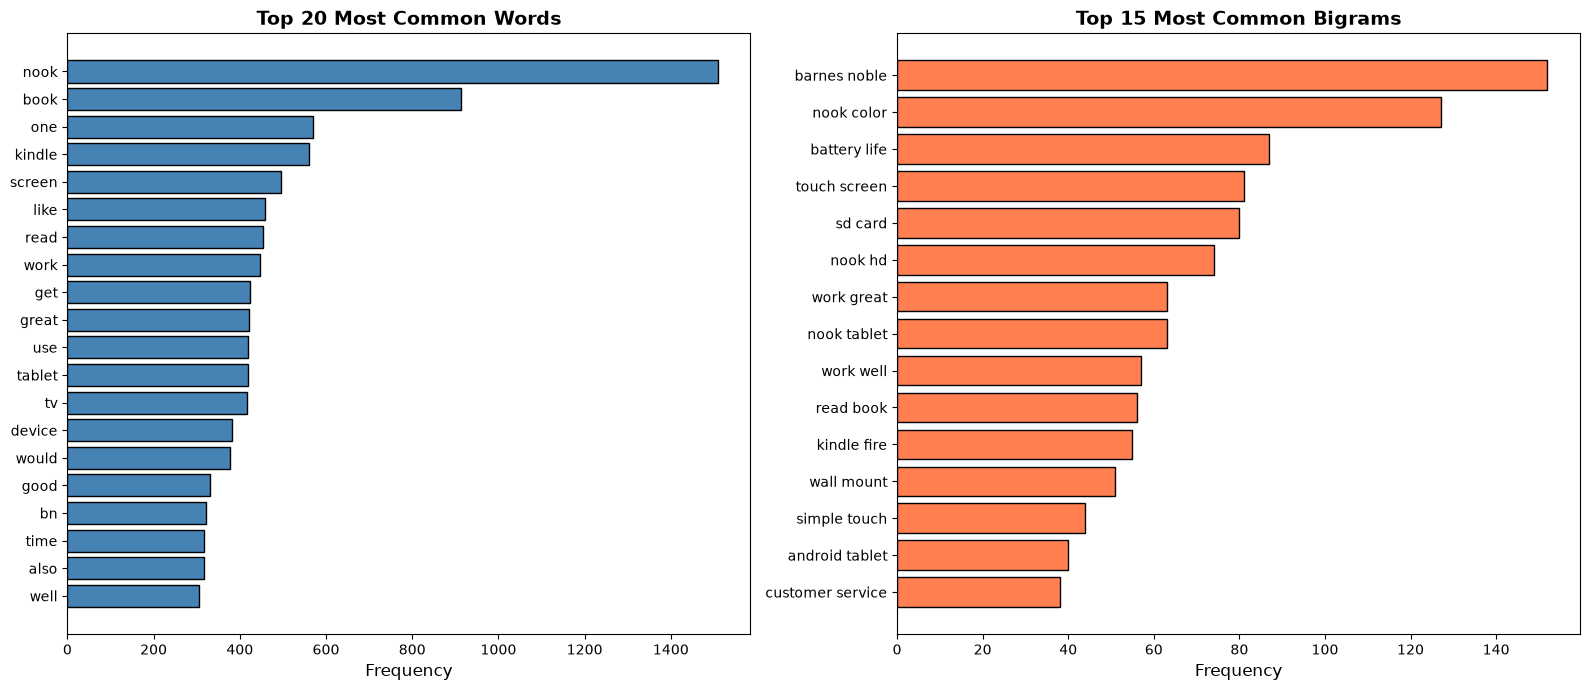

In [11]:

# TODO: Create at least one visualization of the most common words.
# You may also choose to visualize the most common bigrams.
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: Top 20 Most Common Words
top_words = word_freq.most_common(20)
words, counts = zip(*top_words)
axes[0].barh(range(len(words)), counts, color='steelblue', edgecolor='black')
axes[0].set_yticks(range(len(words)))
axes[0].set_yticklabels(words)
axes[0].set_xlabel('Frequency', fontsize=12)
axes[0].set_title('Top 20 Most Common Words', fontsize=14, fontweight='bold')
axes[0].invert_yaxis()

# Plot 2: Top 15 Most Common Bigrams
top_bigrams = bigram_freq.most_common(15)
bigram_labels = [' '.join(bg) for bg, _ in top_bigrams]
bigram_counts = [count for _, count in top_bigrams]
axes[1].barh(range(len(bigram_labels)), bigram_counts, color='coral', edgecolor='black')
axes[1].set_yticks(range(len(bigram_labels)))
axes[1].set_yticklabels(bigram_labels)
axes[1].set_xlabel('Frequency', fontsize=12)
axes[1].set_title('Top 15 Most Common Bigrams', fontsize=14, fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('nlp_word_bigram_freq.png', dpi=150, bbox_inches='tight')
plt.show()


# Reflection prompt:
# What do the most common words or phrases suggest about customer sentiment or product experience?


# Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [2]:
# ==============================
# Part 2: Time Series Starter Code
# ==============================

# TODO: Import the libraries you need.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns


In [4]:

# TODO: Load the same review dataset.
df = pd.read_csv('amazon_reviews_lab.csv')

print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
df.head()


Dataset shape: (997, 9)
Columns: ['product_id', 'rating', 'review_text', 'review_summary', 'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label', 'review_length_words']


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [5]:

# TODO: Convert the timestamp column to datetime format.
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

print("Timestamp dtype:", df['timestamp'].dtype)
print("\nSample timestamps:")
print(df['timestamp'].head(10))
print(f"\nNull timestamps after conversion: {df['timestamp'].isnull().sum()}")


Timestamp dtype: datetime64[us]

Sample timestamps:
0   2000-05-12
1   2002-08-26
2   2005-08-06
3   2005-09-11
4   2007-10-15
5   2008-02-19
6   2008-05-06
7   2008-12-19
8   2009-01-04
9   2009-02-05
Name: timestamp, dtype: datetime64[us]

Null timestamps after conversion: 0


In [6]:


# TODO: Inspect the date range in the dataset.
# Suggested checks:
# - earliest timestamp
# - latest timestamp
earliest = df['timestamp'].min()
latest = df['timestamp'].max()
span_days = (latest - earliest).days

print(f"Earliest timestamp: {earliest}")
print(f"Latest timestamp:   {latest}")
print(f"Date span:          {span_days} days (~{span_days/365:.1f} years)")
print(f"Total reviews:      {len(df)}")


Earliest timestamp: 2000-05-12 00:00:00
Latest timestamp:   2014-07-17 00:00:00
Date span:          5179 days (~14.2 years)
Total reviews:      997


In [ ]:

# TODO: Resample the data by month to calculate:
# 1. monthly review count
# 2. monthly average rating

# Suggested variable names:
# monthly_review_count = ...
# monthly_avg_rating = ...

# TODO: Plot monthly review volume over time.

# TODO: Plot average monthly rating over time.

# TODO: Compute a rolling average for the monthly average rating.
# A 3-month rolling average is a good starting point.

# TODO: Plot both:
# - the original monthly average rating
# - the rolling average
# on the same figure.

# Reflection prompt:
# What overall trends do you notice in review activity and customer ratings over time?


## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [ ]:
# ===================================
# Part 3: Neural Networks Starter Code
# ===================================

# TODO: Import the libraries you need for:
# - data handling
# - train/test splitting
# - text vectorization
# - model building
# - model evaluation

# You will likely need tools from:
# - pandas / numpy
# - sklearn
# - tensorflow / keras

# TODO: Load the dataset.
# df = ...

# TODO: Define:
# X as the review text column
# y as the rating column
# If needed, adjust y so the classes are numbered appropriately for your model.

# TODO: Vectorize the text using TF-IDF.
# Suggested question:
# - How many features do you want to keep?

# vectorizer = ...
# X_tfidf = ...

# TODO: Split the data into training and testing sets.
# Use stratify=y to preserve class balance.

# TODO: One-hot encode the target values if your neural network setup requires it.

# TODO: Build a neural network model.
# Include:
# - an input layer
# - at least one hidden layer
# - an output layer suitable for multi-class classification

# model = ...

# TODO: Compile the model.
# Think about:
# - optimizer
# - loss function
# - evaluation metric(s)

# TODO: Train the model and store the training history.
# history = ...

# TODO: Evaluate the model on the test set.

# TODO: Generate predictions on the test set.

# TODO: Create a classification report and/or confusion matrix to assess performance.

# Reflection prompt:
# Which rating classes does the model predict well, and which ones are harder to classify?
